### **TIDIGITS**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.gmm import GMM
from src.knn import KNN
from src.lda import LDA
from src.pca import PCA
from src.svm import SVM
from src.plotting import plot_pca_2d


### **Load Data**

In [2]:
sequences = []
labels = []
for digit in [1, 5, 6]:
    with np.load(f"./data/tidigits/{digit}.npz") as data:
        for key in data.files:
            sequences.append(data[key])
            labels.append(digit)

y = np.array(labels)

print("Recordings:", len(sequences))
print("Labels:", y.shape)


Recordings: 1350
Labels: (1350,)


### **Shuffle and Split**

In [3]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(y))
train_end = int(0.6 * len(y))
val_end = int(0.8 * len(y))

train_indices = indices[:train_end]
val_indices = indices[train_end:val_end]
test_indices = indices[val_end:]

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]


### **Sequence Length Distribution**

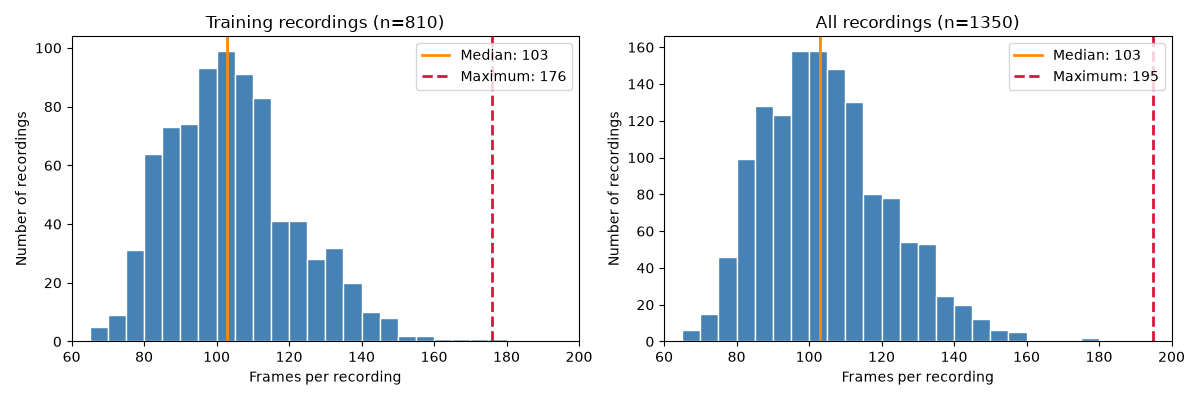

In [4]:
lengths = np.array([len(s) for s in sequences])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, values, title in zip(axes, [lengths[train_indices], lengths],
                            ["Training recordings", "All recordings"]):
    ax.hist(values, bins=np.arange(60, 201, 5), color="steelblue", edgecolor="white")
    ax.axvline(np.median(values), color="darkorange", linewidth=2,
               label=f"Median: {np.median(values):.0f}")
    ax.axvline(values.max(), color="crimson", linestyle="--", linewidth=2,
               label=f"Maximum: {values.max()}")
    ax.set_title(f"{title} (n={len(values)})")
    ax.set_xlabel("Frames per recording")
    ax.set_ylabel("Number of recordings")
    ax.set_xlim(60, 200)
    ax.legend()
plt.tight_layout()
plt.show()


In [5]:
# raw_train_sequences = [sequences[i] for i in train_indices]
# raw_val_sequences = [sequences[i] for i in val_indices]
# raw_test_sequences = [sequences[i] for i in test_indices]
# frame_length = int(np.quantile([len(s) for s in raw_train_sequences], q=0.95))
# print(frame_length)

### **Padding**

In [6]:
raw_train_sequences = [sequences[i] for i in train_indices]
raw_val_sequences = [sequences[i] for i in val_indices]
raw_test_sequences = [sequences[i] for i in test_indices]
frame_length = int(np.median([len(s) for s in raw_train_sequences]))
# frame_length = int(np.quantile([len(s) for s in raw_train_sequences], q=0.95))



def pad_sequences(recordings):
    padded = []
    for recording in recordings:
        values = np.zeros((frame_length, recording.shape[1]))
        count = min(len(recording), frame_length)
        values[:count] = recording[:count]
        padded.append(values)
    return padded


train_sequences = pad_sequences(raw_train_sequences)
val_sequences = pad_sequences(raw_val_sequences)
test_sequences = pad_sequences(raw_test_sequences)
X_train = np.array(train_sequences).reshape(len(train_sequences), -1)
X_val = np.array(val_sequences).reshape(len(val_sequences), -1)
X_test = np.array(test_sequences).reshape(len(test_sequences), -1)
print("Target frames:", frame_length)


Target frames: 103


In [7]:
X_train.shape

In [8]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [1 5 6]
Train: (810, 4017)
Validation: (270, 4017)
Test: (270, 4017)


### **Training Coordinates for GMM and LDA**

In [9]:
feature_mean = X_train.mean(axis=0)
_, _, vectors = np.linalg.svd(X_train - feature_mean, full_matrices=False)
basis = vectors.T
X_train_gaussian = (X_train - feature_mean) @ basis
X_val_gaussian = (X_val - feature_mean) @ basis
X_test_gaussian = (X_test - feature_mean) @ basis
print("All training directions retained:", X_train_gaussian.shape)


All training directions retained: (810, 810)


### **2D PCA Visualization**

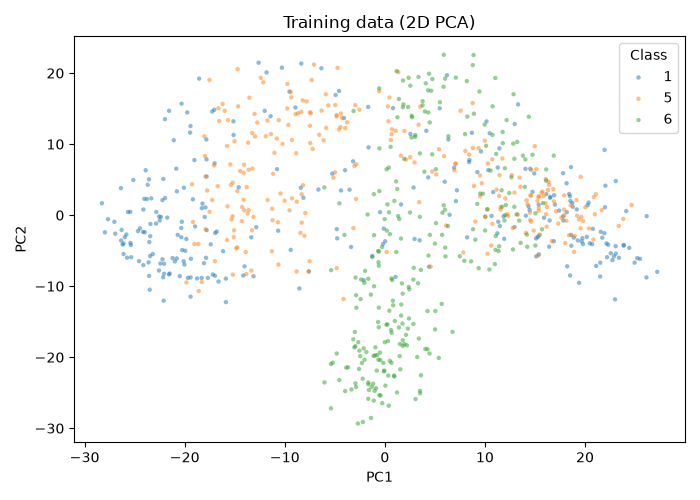

In [10]:
plot_pca_2d(X_train_gaussian, y_train)


### **GMM**

In [11]:
models = []
priors = []
for label in classes:
    samples = X_train_gaussian[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train_gaussian))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 1 EM iterations: 2
Class 5 EM iterations: 2
Class 6 EM iterations: 2


In [12]:
val_scores = np.column_stack([model.score_samples(X_val_gaussian) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test_gaussian) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [13]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.8629629629629629
Test accuracy: 0.8777777777777778
Test confusion matrix:
 [[88  0  0]
 [28 64  2]
 [ 3  0 85]]


### **KNN**

In [14]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [15]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.9333333333333333
Test accuracy: 0.9592592592592593
Test confusion matrix:
 [[88  0  0]
 [ 6 88  0]
 [ 5  0 83]]


### **LDA**

In [16]:
lda = LDA()
lda.fit(X_train_gaussian, y_train)
lda_val_predictions = lda.predict(X_val_gaussian)
lda_test_predictions = lda.predict(X_test_gaussian)


In [17]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.9222222222222223
Test accuracy: 0.9333333333333333
Test confusion matrix:
 [[84  4  0]
 [ 9 83  2]
 [ 3  0 85]]


### **SVM**

In [18]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 3
Gaussian sigma: 30.50274466333877
Converged: True
Largest KKT gap: 0.0009984584705344801


In [19]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.9444444444444444
Test accuracy: 0.9444444444444444
Test confusion matrix:
 [[82  1  5]
 [ 3 86  5]
 [ 0  1 87]]


### **PCA**

In [20]:
K = 39
pca = PCA(k=K)
pca.fit(X_train_gaussian)
X_train_pca = pca.transform(X_train_gaussian)
X_val_pca = pca.transform(X_val_gaussian)
X_test_pca = pca.transform(X_test_gaussian)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (810, 39)
Validation: (270, 39)
Test: (270, 39)


### **GMM with PCA**

In [21]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 1 EM iterations: 2
Class 5 EM iterations: 2
Class 6 EM iterations: 2


In [22]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [23]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.9444444444444444
Test accuracy: 0.9666666666666667
Test confusion matrix:
 [[85  3  0]
 [ 4 89  1]
 [ 0  1 87]]


### **KNN with PCA**

In [24]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [25]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.9518518518518518
Test accuracy: 0.9777777777777777
Test confusion matrix:
 [[86  2  0]
 [ 1 93  0]
 [ 2  1 85]]


### **LDA with PCA**

In [26]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [27]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.837037037037037
Test accuracy: 0.8222222222222222
Test confusion matrix:
 [[73 15  0]
 [17 69  8]
 [ 7  1 80]]


### **SVM with PCA**

In [28]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 3
Gaussian sigma: 19.856670301891523
Converged: True
Largest KKT gap: 0.0009950036454260403


In [29]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.9629629629629629
Test accuracy: 0.9777777777777777
Test confusion matrix:
 [[87  1  0]
 [ 2 91  1]
 [ 1  1 86]]


### **Accuracy Comparison**

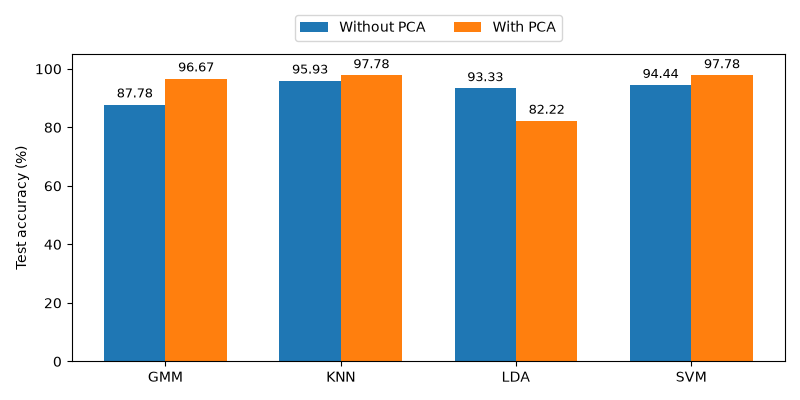

In [30]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()
